# SABR integration labels: McGhee §3.2

The standalone generator is [`src/integration.py`](src/integration.py). This notebook explains the calculation and reproduces Table 6. **Run All runs only the small checks and plot.** Start the full resumable generation from a terminal using the command at the end.

We keep the paper's original conditional-lognormal (LN) approximation, $F_0=1$, $\beta=1$, both maturity windows and ten IV labels per smile. The ANN comparison in [`AQF_S2_ANN_Hagan.ipynb`](AQF_S2_ANN_Hagan.ipynb) keeps both the paper inputs and the log-transformed inputs at all four widths: 250, 500, 750 and 1000. Existing weights are reused.

**Prices → implied volatilities → training labels.** Integration computes option prices first. Each price is then inverted through Black's formula to obtain an annualized implied volatility. Monte Carlo prices could be converted in exactly the same way, but their sampling and time-step errors would also affect the IV labels.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from src.hagan import hagan_iv
from src.integration import (
    check_against_paper,
    conditional_mean_variance,
    conditional_second_moment,
    invert_otm,
    quadrature_price,
)

## 1. Conditional pricing

The model is
$$dF_t=\sigma_tF_t\,dW_t^{(1)},\qquad d\sigma_t=\nu\sigma_t\,dW_t^{(2)},
\qquad d\langle W^{(1)},W^{(2)}\rangle_t=\rho\,dt,\quad \sigma_0=\alpha.$$
Write $s=\sigma_T$ and $v=T^{-1}\int_0^T\sigma_t^2dt$. Conditional on these quantities,
$$F_c(s,v)=F_0\exp\!\left(\frac{\rho}{\nu}(s-\alpha)-\frac{\rho^2vT}{2}\right),
\qquad\sigma_c(s,v)=\sqrt{(1-\rho^2)v}.$$
Averaging the conditional Black price over the joint law of $(s,v)$ gives the option price. The conditional Black representation is exact; the paper approximates the conditional law of $v$.

Prices are undiscounted. Choose puts for $K<F_0$ and calls otherwise, as in paper Table 7. We compute the raw payoff expectation without forward rescaling or put-call parity substitution.

## 2. Conditional moments

Match $m_1(s)=E[v\mid s]$ and $m_2(s)=E[v^2\mid s]$. For $q=T+\log(s/\alpha)/\nu^2$, the paper's first moment is
$$m_1(s)=\frac{\alpha^2\sqrt{2\pi T}}{2\nu T}e^{\nu^2q^2/(2T)}
\left[\Phi\!\left(\frac{\nu(2T-q)}{\sqrt T}\right)-\Phi\!\left(-\frac{\nu q}{\sqrt T}\right)\right].$$
The implementation uses survival probabilities where subtracting two CDFs near one would lose precision.

The second moment is evaluated using this equivalent positive integral, with $\ell=\log(s/\alpha)$ and $u=\nu^2T$:
$$m_2(s)=\alpha^4\int_0^1 e^{2ut(1-t)}\frac{\operatorname{expm1}(2ut)}{2u}
\left[e^{2\ell t}+e^{2\ell(2-t)}\right]dt.$$
A 32-point Gauss–Legendre rule avoids cancellation in the closed form. This evaluates the same moment; it does not change the fitted distribution. The conditional variance is $m_2-m_1^2$, not $m_2$.

In [2]:
# Reference values retained from the original notebook.
np.testing.assert_allclose(
    conditional_mean_variance(.3, .8, .25, .45), .14628716454135107, rtol=1e-11)
np.testing.assert_allclose(
    conditional_second_moment(.2, .5, 1., [.1, .2, .4]),
    [.0006004481090664684, .0020674118127241383, .009607169745063494], rtol=1e-11)
print('Conditional moment checks passed.')

Conditional moment checks passed.


## 3. Original conditional-lognormal (LN) integration

For independent $Z_1,Z_2\sim N(0,1)$,
$$s=\alpha e^{-\nu^2T/2+\nu\sqrt T Z_1}.$$
Match a conditional lognormal distribution to $m_1(s),m_2(s)$:
$$\tau^2(s)=\log\frac{m_2(s)}{m_1(s)^2},\qquad
\mu(s)=\log m_1(s)-\frac{\tau^2(s)}{2},\qquad
v_{\rm LN}=e^{\mu(s)+\tau(s)Z_2}.$$

For $\beta=1$, conditioning on $(s,v)$ gives the effective forward and volatility
$$F_c(s,v)=F_0\exp\!\left[\frac{\rho}{\nu}(s-\alpha)-\frac{\rho^2vT}{2}\right],
\qquad \sigma_c(s,v)=\sqrt{(1-\rho^2)v}.$$
The conditional Black representation is exact when $(s,v)$ has its true joint law. The LN approximation changes that law. Its option value is formally
$$V_{\rm LN}=\int_{\mathbb R}\!\int_{\mathbb R}
B_{\rm option}(F_c(s(z_1),v(z_1,z_2)),K,T,\sigma_c)
\phi(z_1)\phi(z_2)\,dz_2dz_1.$$

For a tensor-product Gauss-Hermite rule with normalized standard-normal weights,
$$V_n\approx\sum_{i=1}^n\sum_{j=1}^n w_iw_j B_{\rm option}(F_{c,ij},K,T,\sigma_{c,ij}).$$
`roots_hermitenorm(n)` supplies weights for $e^{-z^2/2}$, so divide them by $\sqrt{2\pi}$. Here **64 points means 64 points in each dimension**, or $64^2$ conditional nodes. The base calculation evaluates both $64^2$ and $128^2$ nodes.

The implementation uses log-CDFs and log-sum-exp to avoid avoidable numerical overflow and subtraction error. These changes do not regularize a divergent integral. OTM direction is selected against the original $F_0$: put when $K<F_0$, call otherwise.

## 4. Acceptance and the positive-correlation limitation

Calculate prices at 64² and 128² Gauss–Hermite nodes, invert both to Black IV, and accept only when
$$10^4|\sigma_{128}-\sigma_{64}|\le0.1\text{ IV bp}.$$
The saved label is $\sigma_{128}$; other labels remain `NaN`. There is no automatic higher-order refinement. Agreement is a numerical diagnostic, not a bound on error against exact SABR.

**Positive-correlation calls:** extending this fitted LN law over its full support produces a divergent call expectation. This problem belongs to the approximation; true SABR call expectations remain finite. Those labels are always `NaN`, even if a finite quadrature rule returns a finite number. For large terminal volatility $s$, the LN fit permits variance too small to offset the positive $\rho s/\nu$ term in $\log F_c$. The full derivation is retained in the collapsed details below.

For positive correlation, true lognormal SABR can also be a strict local martingale. Raw calls and calls inferred from puts using $F_0$ can then differ. We retain the original raw OTM convention throughout.

The shifted-lognormal modification is omitted to follow the paper's distribution. Fine-tuning must explicitly handle missing labels; the current unmasked MSE trainer cannot consume these arrays directly.

<details>
<summary>Why the LN positive-correlation call tail diverges</summary>

**Asymptotic argument.** Put $u=\nu^2T$ and $\ell=\log(s/\alpha)$. The exact conditional moments have the large-$s$ expansions
$$m_1(s)=\frac{s^2}{2\ell}\left(1+\frac{u}{\ell}+O(\ell^{-2})\right),$$
$$m_2(s)=\frac{s^4}{4\ell^2}\left(1+\frac{3u}{\ell}+O(\ell^{-2})\right),
\qquad \tau^2(s)\sim\frac{u}{\ell}.$$
The fitted LN law still gives positive probability to $v\in[bs/2,bs]$, whose logarithmic probability behaves as
$$\log\Pr(bs/2\le v\le bs\mid s)
=-\frac{\ell^3}{2u}(1+o(1)).$$
Choose any fixed $0<b<2/(\rho\nu T)$. On this event,
$$\log F_c\ge\log F_0-\frac{\rho\alpha}{\nu}
+\underbrace{\left(\frac{\rho}{\nu}-\frac{\rho^2Tb}{2}\right)}_{c>0}s.$$
Because $B_C(F_c,K,\cdot)\ge(F_c-K)^+$, the conditional contribution eventually grows at least like a positive constant times
$$\exp\left(c\alpha e^\ell-\frac{\ell^3}{2u}(1+o(1))\right).$$
The outer normal density of $\ell\sim N(-u/2,u)$ contributes only an additional quadratic exponential decay. It cannot dominate the $e^\ell$ term in the exponent. Hence the full call integral diverges.

**Useful distinctions.** Puts are bounded by $K$. For $\rho\le0$, $F_c\le F_0e^{-\rho\alpha/\nu}$, so the same call-tail mechanism is absent. For the true nonnegative SABR local martingale, $E[F_T]\le F_0$, hence its raw call payoff has a finite expectation. The approximate LN joint distribution has lost the required tail dependence.


</details>

## 5. Reproduce Table 6

The published integration and FDM values are rounded. This negative-correlation example checks reproduction of the paper; it does not establish accuracy across the full parameter domain.

Max error vs. rounded paper integration IVs: 0.5121 bp


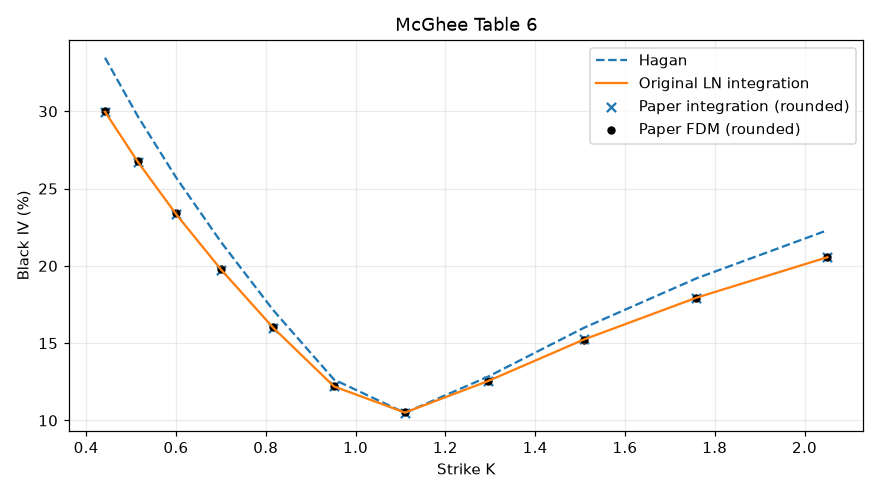

In [3]:
K = np.array([.4419, .5152, .6007, .7004, .8166, .9520, 1.1100, 1.2941, 1.5088, 1.7591, 2.0509])
paper_ln = np.array([29.97, 26.72, 23.33, 19.76, 16., 12.20, 10.51, 12.54, 15.24, 17.94, 20.56]) / 100
paper_fdm = np.array([30.02, 26.78, 23.39, 19.81, 16.05, 12.23, 10.53, 12.55, 15.23, 17.93, 20.56]) / 100
T, alpha, nu, rho = 1.6316, .108266, .887903, -.464053
iv_ln = invert_otm(quadrature_price(1., K, T, alpha, rho, nu), K, T)
error = check_against_paper()
assert error < 1., f'Table 6 reproduction failed: {error:.4f} bp'
print(f'Max error vs. rounded paper integration IVs: {error:.4f} bp')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(K, 100 * hagan_iv(1., K, T, alpha, 1., rho, nu), '--', label='Hagan')
ax.plot(K, 100 * iv_ln, label='Original LN integration')
ax.scatter(K, 100 * paper_ln, marker='x', label='Paper integration (rounded)')
ax.scatter(K, 100 * paper_fdm, color='black', s=20, label='Paper FDM (rounded)')
ax.set(xlabel='Strike K', ylabel='Black IV (%)', title='McGhee Table 6')
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()

## 6. Paper-aligned parameter and strike sampling

Each maturity window has its own dataset:

| Quantity | Paper setting |
|---|---|
| Expiry windows | $[1/365,1]$ and $[1,2]$ |
| Initial volatility | $\alpha\sim U(0.05,0.5)$ |
| Correlation | $\rho\sim U(-0.9,0.9)$ |
| One-month vol-of-vol | $\nu_{1M}\sim U(0.05,4)$ |
| Actual vol-of-vol | $\nu=\nu_{1M}\sqrt{(1/12)/T}$ |
| Training set per window | 100000 grid rows + 150000 random rows |
| Test set per window | 50000 independent random rows |
| Original grid | $100\times10\times10\times10$ points in $T,\alpha,\nu_{1M},\rho$ |

One **row** is one parameter set and contains **ten IV labels**. Therefore 300000 rows per window means 3 million labels; both windows mean 600000 rows and 6 million labels **per pricing method**. Random seeds here are implementation choices, not seeds disclosed by the paper.

For the strikes, define $u=\nu^2T$ and the unconditional mean average variance
$$\bar v=\alpha^2\frac{e^u-1}{u}.$$
Use the terminal-volatility scenario
$$s_* = \alpha e^{-u/2+1.5\nu\sqrt T},\qquad \Delta\sigma=s_*-\alpha,$$
and
$$K_j=F_0\exp\!\left(-\frac{\bar vT}{2}+\frac{\rho}{\nu}\Delta\sigma
+\eta_j\sqrt{\bar vT}\right),\qquad
\eta_j=-3.5+\frac{7j}{9},\quad j=0,\ldots,9.$$

Sampling and strikes are reused from `src/hagan.py`, following the unconditional mean variance in paper Eq. (46) and Tables 3–4. The first window uses the existing seeds (42, 43, 44), so its input rows and ordering match `data/datasets/hagan_1d_1y.npz` exactly. The second uses (45, 46, 47). Seeds are implementation choices, not published paper settings.

## 7. Run the resumable generator

From the repository root:

```bash
uv run python -m src.integration
```

This generates all 600,000 rows using the available CPU cores. Use `--workers 4` to limit processes.

Chunks of 100 rows are atomically saved in `data/chunks/ln_parity_parts/{window}/{train,test}/`. Rerun the same command after interruption to reuse saved chunks; input rows are checked when the chunks are assembled, and an interrupted temporary file is recomputed.

Completed windows are assembled into `data/datasets/ln_parity_1d_1y.npz` and `data/datasets/ln_parity_1y_2y.npz`, each containing `X_train`, `y_train`, `X_test`, `y_test`, maturity range, seeds and quadrature settings. Inputs have 14 columns `[T, alpha, nu, rho, K1, ..., K10]`; labels have 10 columns of annualized IVs as decimals. Missing labels remain `NaN`. No fine-tuning starts automatically.

Once a window is complete, inspect coverage with:

```python
with np.load('data/datasets/ln_parity_1d_1y.npz') as d:
    y = d['y_train']
    print('Finite labels:', np.isfinite(y).mean())
    print('Complete smiles:', np.isfinite(y).all(axis=1).mean())
```

Source: [McGhee paper](wiki/research/mcghee-2018-sabr-ann.pdf), §3.2 (integration), §4 (sampling and widths), §5.2–5.3 and Tables 6–7. The paper does not disclose a tail-handling rule that would resolve the LN divergence described above. Our finite-node implementation and explicit missing-label policy should therefore be distinguished from the author's unpublished implementation.